# TSLA — Five-model forecasting comparison
**AMS 586 · One-step-ahead closing-price forecasts**

This presentation notebook is **read-only**: it consumes the frozen test CSVs and the append-only prospective forecast histories exported by the five individual model notebooks. It does **not** download prices, refit models, change parameters, or overwrite forecasts. Run each model notebook first when fresh forecasts are needed.

**Experimental protocol:** train → validation (hyperparameter selection and empirical residual calibration) → frozen test (258 daily targets, ending November 19, 2026) → prospective forecasts. Intervals are nominal 95% empirical intervals: residual-shift for RW, RW + drift, ARIMA and MLP; volatility-scaled standardized residuals for ARIMA-GARCH; nominal coverage is not a guarantee of conditional coverage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

# Locate project root regardless of whether notebook is run from root or stock_pred/notebooks.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "stock_pred" / "results").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project containing stock_pred/results")
RESULTS_DIR = PROJECT_ROOT / "stock_pred" / "results"

MODEL_FILES = {
    "Random Walk": "random_walk",
    "Random Walk + Drift": "random_walk_drift",
    "ARIMA(0,1,1)": "arima",
    "MLP": "mlp",
    "ARIMA-GARCH(1,1)-t": "arima_garch",
}
INTERVAL_LEVEL = 0.95
EXPECTED_TEST_COUNT = 258
TEST_END_DATE = pd.Timestamp("2026-11-19")
print("Reading exported results from:", RESULTS_DIR)

from shared_code.visualization.exporting import (
    save_figure,
    save_table,
)

FIGURES_DIR = PROJECT_ROOT / "stock_pred" / "figures" / "model_comparison"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

Reading exported results from: /Users/haifengwu/SBUCSE/AMS586/time-series-forecasting/stock_pred/results


## 1 · Load and validate the exported datasets
The comparison requires **identical test target dates and actual prices** for every model. It fails rather than silently comparing mismatched experiments.

In [2]:
REQUIRED = ["origin_date", "target_date", "model", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]

def load_result(prefix, suffix):
    path = RESULTS_DIR / f"{prefix}_{suffix}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run the corresponding model notebook first.")
    df = pd.read_csv(path, parse_dates=["origin_date", "target_date"])
    missing = set(REQUIRED) - set(df.columns)
    if missing:
        raise ValueError(f"{path.name}: missing {sorted(missing)}")
    if df["target_date"].duplicated().any():
        raise ValueError(f"{path.name}: duplicate target dates; inspect before comparing")
    if not (df["origin_date"] < df["target_date"]).all():
        raise ValueError(f"{path.name}: origin must precede target")
    for col in REQUIRED[3:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df.sort_values("target_date").reset_index(drop=True)

tests = {name: load_result(prefix, "test") for name, prefix in MODEL_FILES.items()}
live = {name: load_result(prefix, "live_history") for name, prefix in MODEL_FILES.items()}

reference = tests["Random Walk"]
assert len(reference) == EXPECTED_TEST_COUNT, f"Expected {EXPECTED_TEST_COUNT} test targets; got {len(reference)}"
assert reference["target_date"].max() == TEST_END_DATE
for name, df in tests.items():
    pd.testing.assert_series_equal(df["target_date"], reference["target_date"], check_names=False)
    np.testing.assert_allclose(df["y_true"], reference["y_true"], rtol=0, atol=1e-6)
    if df[["y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].isna().any().any():
        raise ValueError(f"{name}: missing values in frozen test predictions")
    if (df["interval_lower"] > df["interval_upper"]).any():
        raise ValueError(f"{name}: inverted intervals")

print(f"Validated {len(reference)} identical test targets: {reference.target_date.min().date()} to {reference.target_date.max().date()}")
display(pd.DataFrame([{"Model": name, "Test rows": len(tests[name]),
                       "Prospective rows": len(live[name]),
                       "Latest prospective target": live[name].target_date.max().date() if len(live[name]) else None}
                      for name in MODEL_FILES]))

Validated 258 identical test targets: 2025-11-11 to 2026-11-19


,Model,Test rows,Prospective rows,Latest prospective target
0,Random Walk,258,4,2026-11-30
1,Random Walk + Drift,258,3,2026-11-30
2,"ARIMA(0,1,1)",258,3,2026-11-30
3,MLP,258,3,2026-11-30
4,"ARIMA-GARCH(1,1)-t",258,1,2026-11-30


## 2 · Untouched test performance
All point metrics are evaluated against the **same actual closing prices**. The empirical predictive mean is also evaluated as a separate point forecast. The MSE and RMSE optimize squared-error accuracy; MAE reports average absolute error in dollars.

**Coverage** is the fraction of observed closes inside the nominal 95% prediction interval. **Width** measures how informative the interval is. Wider intervals can increase coverage without improving precision.

In [3]:
from shared_code.evaluation.metrics import interval_score

def score_forecasts(df):
    actual = df["y_true"].to_numpy(float)
    pred = df["y_pred"].to_numpy(float)
    pm = df["predictive_mean"].to_numpy(float)
    err = actual - pred
    covered = (actual >= df["interval_lower"].to_numpy(float)) & (actual <= df["interval_upper"].to_numpy(float))
    return {
        "RMSE ($)": np.sqrt(np.mean(err**2)),
        "MAE ($)": np.mean(np.abs(err)),
        "MSE ($²)": np.mean(err**2),
        "Bias ($)": np.mean(err),
        "Predictive mean RMSE ($)": np.sqrt(np.mean((actual - pm)**2)),
        "Coverage (%)": 100*np.mean(covered),
        "Avg interval width ($)": np.mean(df["interval_upper"]-df["interval_lower"]),
        # Winkler score: width + (2/alpha) x miss distance; lower is better.
        "Interval score ($)": interval_score(actual, df["interval_lower"].to_numpy(float),
                                             df["interval_upper"].to_numpy(float), INTERVAL_LEVEL),
    }

scores = pd.DataFrame({name: score_forecasts(df) for name, df in tests.items()}).T
scores.index.name = "Model"
scores = scores.sort_values("RMSE ($)")
display(scores.round(3))
print("Lowest test RMSE:", scores.index[0], "(descriptive only: do not retune models using the test set)")

,RMSE ($),MAE ($),MSE ($²),Bias ($),Predictive mean RMSE ($),Coverage (%),Avg interval width ($),Interval score ($)
Model,,,,,,,,
Random Walk,11.239,8.479,126.305,-0.274,11.268,97.287,51.690,62.008
"ARIMA-GARCH(1,1)-t",11.249,8.491,126.536,-0.413,11.287,95.736,44.125,59.907
"ARIMA(0,1,1)",11.259,8.552,126.756,-0.302,11.289,97.287,50.552,62.012
Random Walk + Drift,11.271,8.482,127.040,-0.455,11.273,97.287,51.741,61.822
MLP,11.559,8.781,133.600,-0.573,11.550,97.287,54.635,63.302


Lowest test RMSE: Random Walk (descriptive only: do not retune models using the test set)


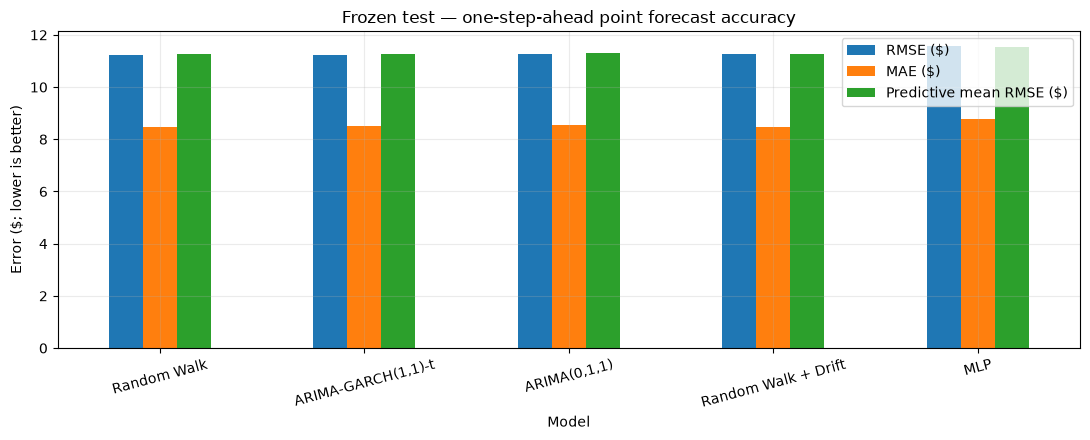

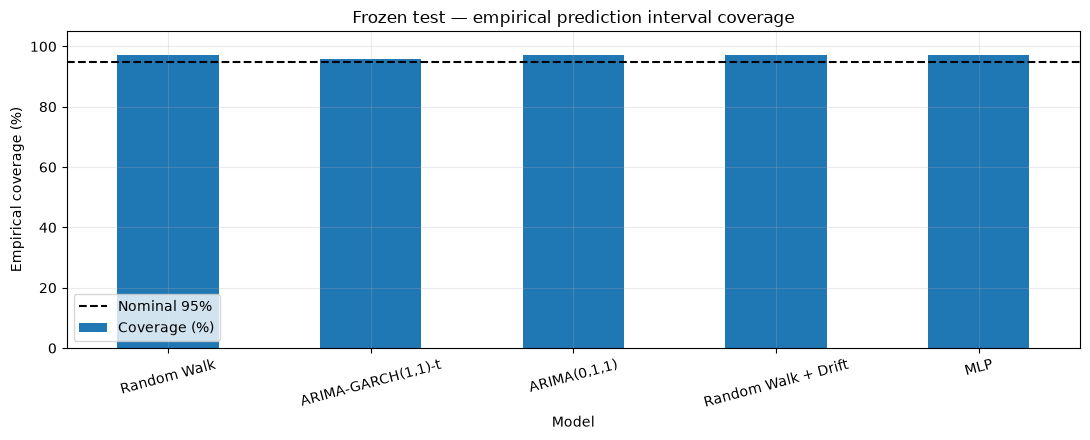

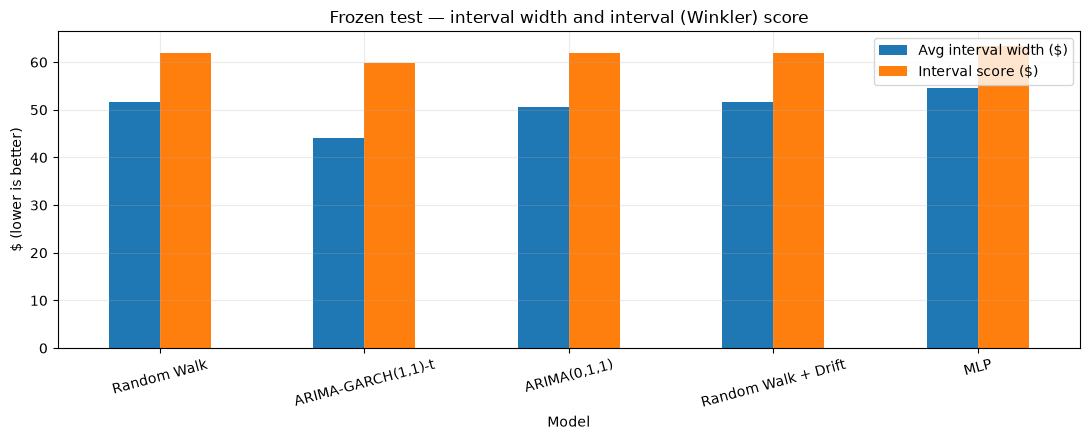

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
scores[["RMSE ($)", "MAE ($)", "Predictive mean RMSE ($)"]].plot.bar(ax=ax, rot=15)
ax.set_title("Frozen test — one-step-ahead point forecast accuracy")
ax.set_ylabel("Error ($; lower is better)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
scores["Coverage (%)"].plot.bar(ax=ax, rot=15)
ax.axhline(100*INTERVAL_LEVEL, color="black", linestyle="--", label="Nominal 95%")
ax.set_ylim(0, 105); ax.set_ylabel("Empirical coverage (%)")
ax.set_title("Frozen test — empirical prediction interval coverage")
ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
scores[["Avg interval width ($)", "Interval score ($)"]].plot.bar(ax=ax, rot=15)
ax.set_title("Frozen test — interval width and interval (Winkler) score")
ax.set_ylabel("$ (lower is better)")
plt.tight_layout(); plt.show()

## 3 · Aligned actual vs. forecast paths
These plots share identical test dates. The display is restricted to the last 75 test sessions for readability; the metrics above use **all 258** sessions.

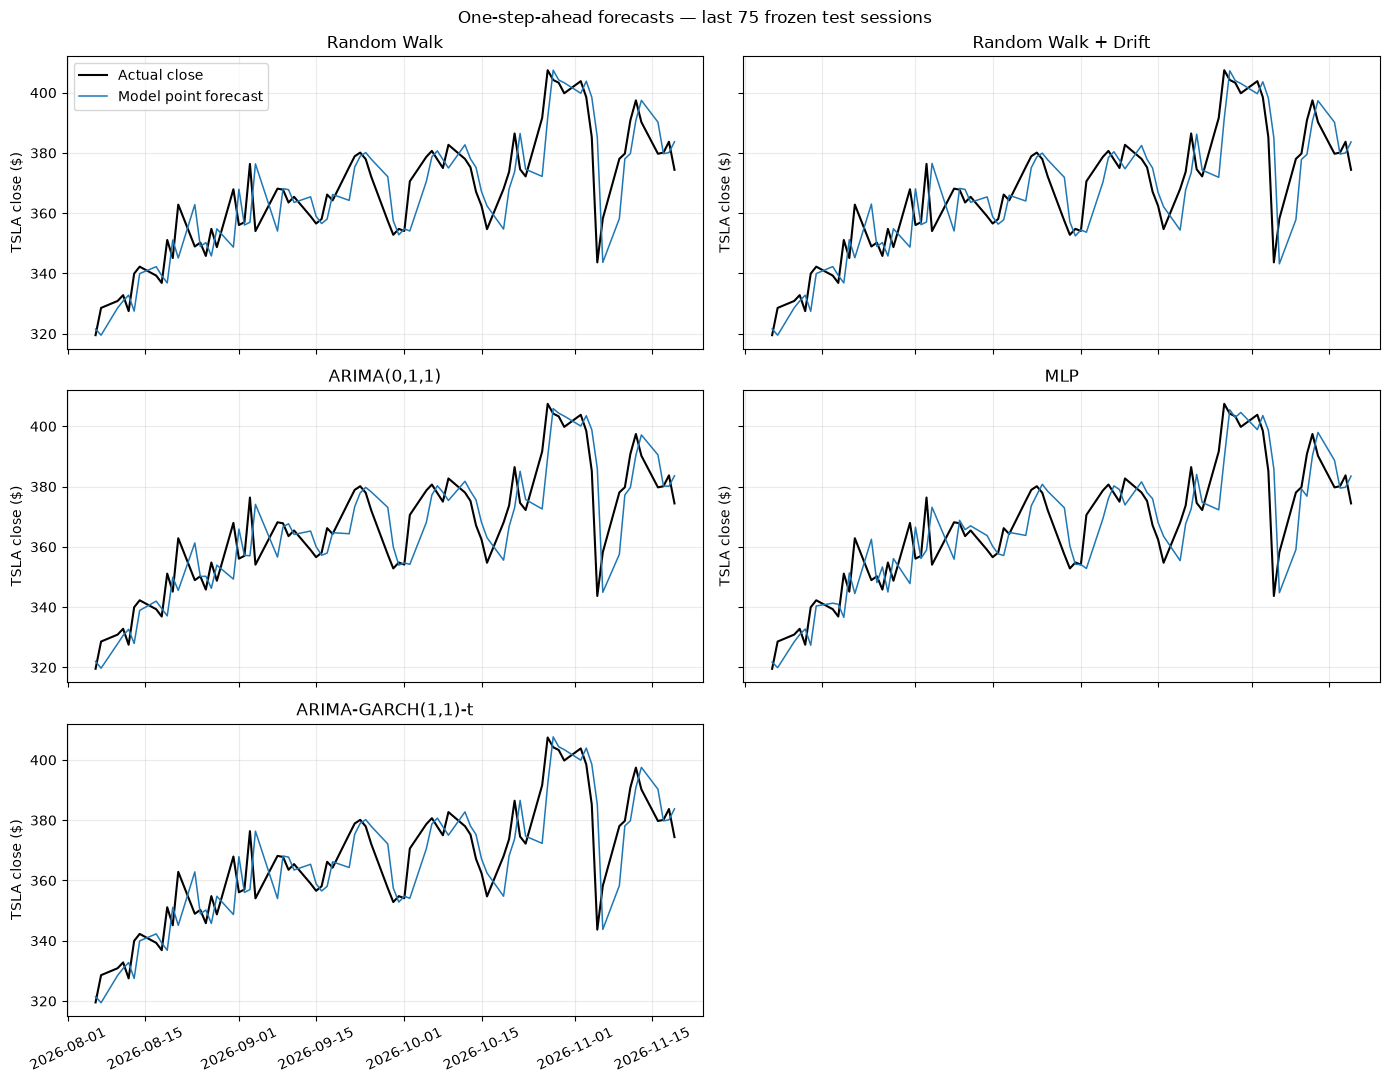

In [5]:
last_n = 75
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True, sharey=True)
for ax, (name, df) in zip(axes.flat, tests.items()):
    view = df.tail(last_n)
    ax.plot(view.target_date, view.y_true, label="Actual close", color="black", lw=1.5)
    ax.plot(view.target_date, view.y_pred, label="Model point forecast", lw=1.1)
    ax.set_title(name); ax.set_ylabel("TSLA close ($)")
    ax.tick_params(axis="x", rotation=25)
axes.flat[0].legend(loc="best")
fig.suptitle("One-step-ahead forecasts — last 75 frozen test sessions")
for ax in axes.flat[len(tests):]:
    ax.set_visible(False)  # hide unused panels
plt.tight_layout(); plt.show()

## 4 · Forecast-error diagnostics
The signed forecast error is $e_t=P_t-\widehat P_{t|t-1}$. A small **mean** error does not imply small individual errors. RMSE squares before averaging; MAE takes absolute values before averaging.

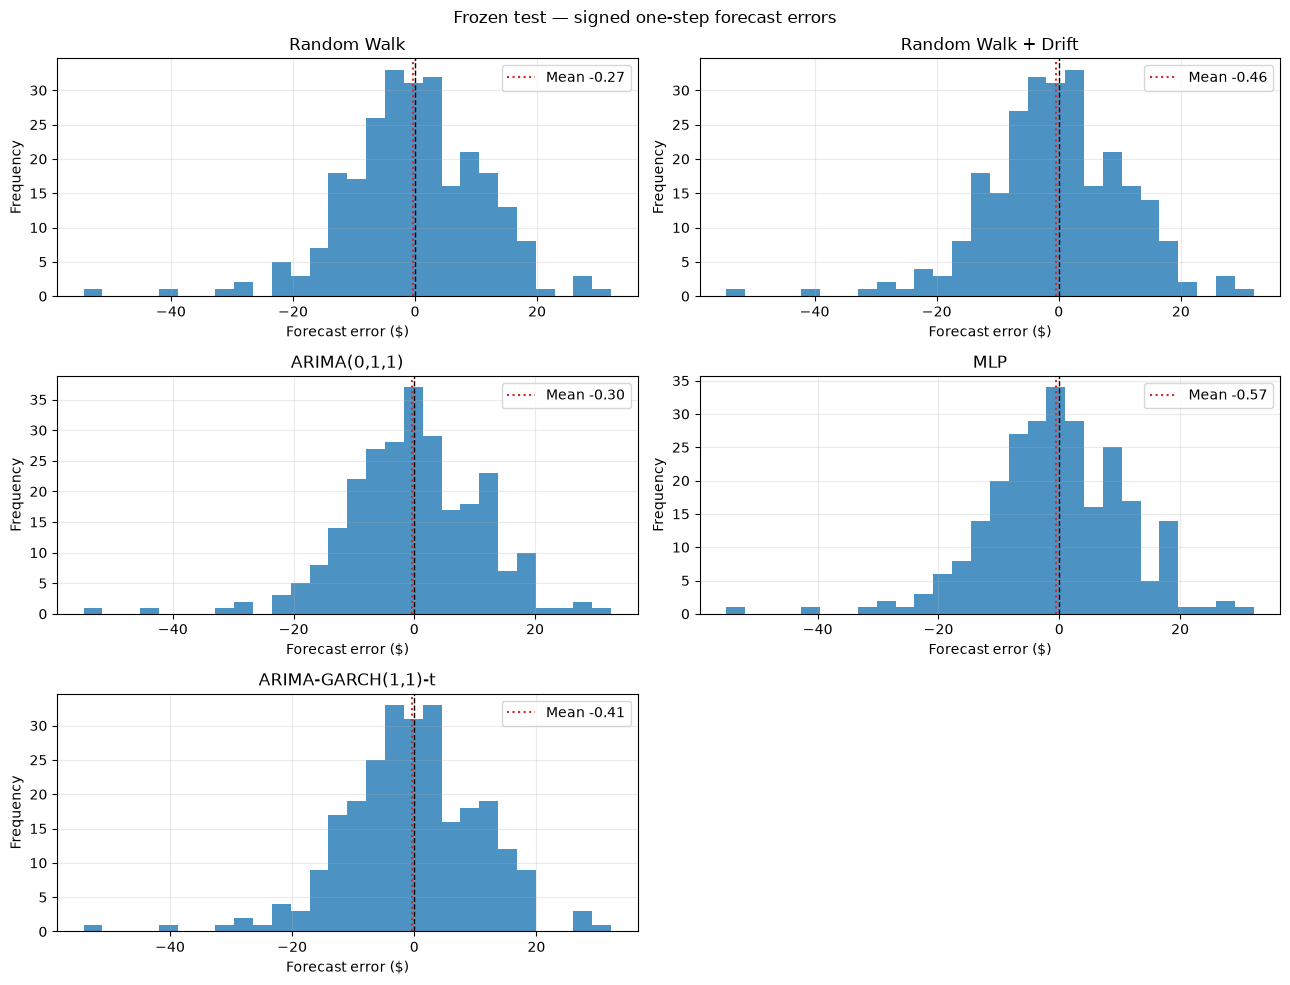

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, (name, df) in zip(axes.flat, tests.items()):
    errors = df.y_true - df.y_pred
    ax.hist(errors, bins=28, alpha=0.8)
    ax.axvline(0, color="black", linestyle="--", lw=1)
    ax.axvline(errors.mean(), color="tab:red", linestyle=":", lw=1.5, label=f"Mean {errors.mean():.2f}")
    ax.set_title(name); ax.set_xlabel("Forecast error ($)"); ax.set_ylabel("Frequency"); ax.legend()
fig.suptitle("Frozen test — signed one-step forecast errors")
for ax in axes.flat[len(tests):]:
    ax.set_visible(False)  # hide unused panels
plt.tight_layout(); plt.show()

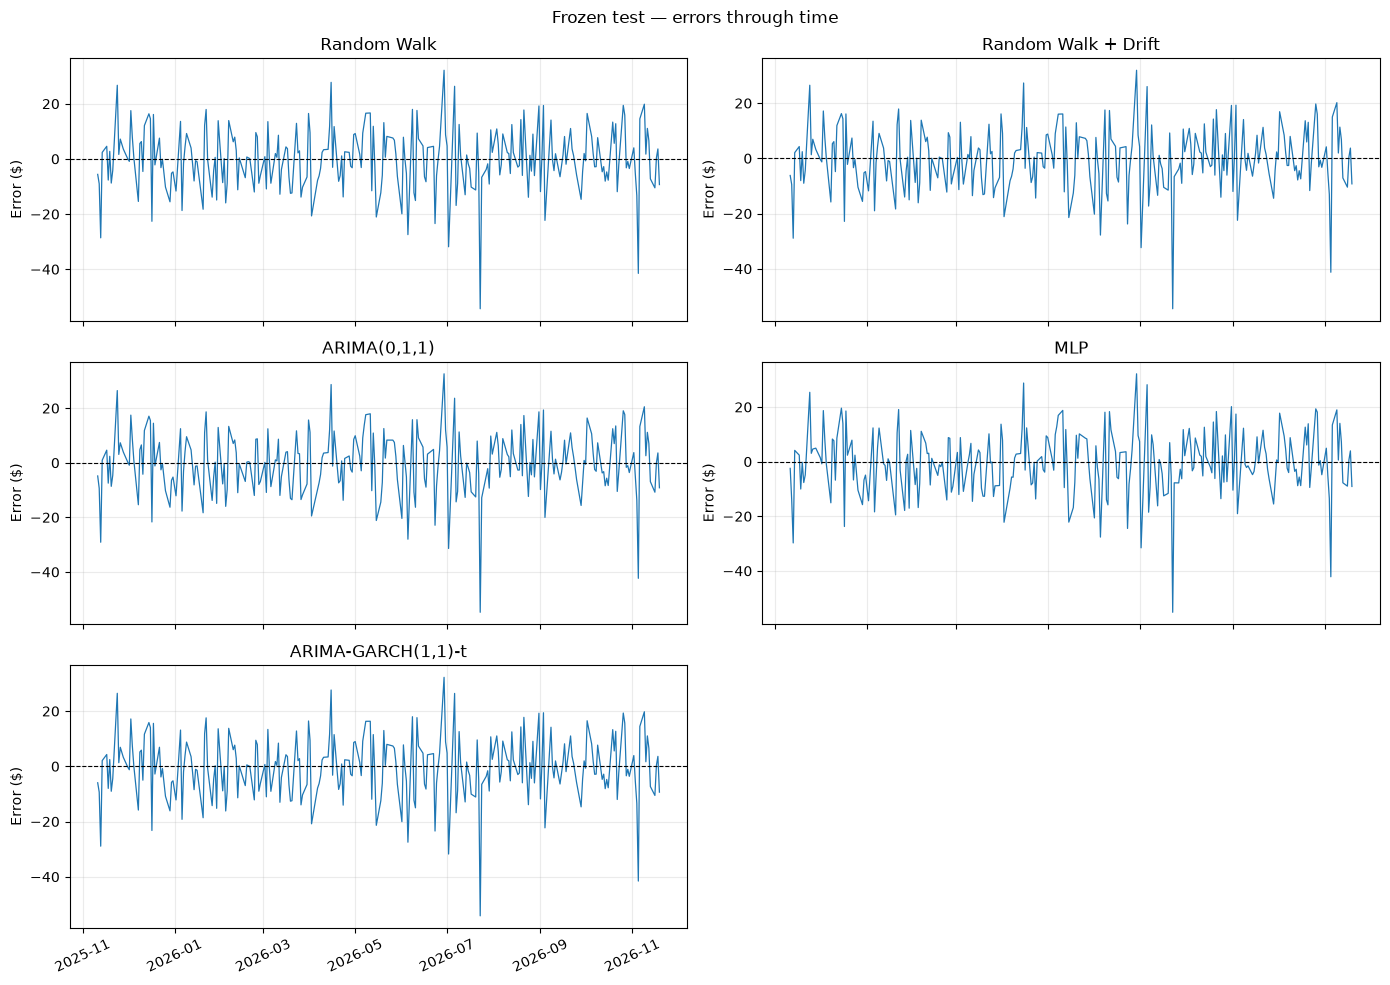

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, (name, df) in zip(axes.flat, tests.items()):
    errors = df.y_true - df.y_pred
    ax.plot(df.target_date, errors, lw=0.9)
    ax.axhline(0, color="black", linestyle="--", lw=0.8)
    ax.set_title(name); ax.set_ylabel("Error ($)"); ax.tick_params(axis="x", rotation=25)
fig.suptitle("Frozen test — errors through time")
for ax in axes.flat[len(tests):]:
    ax.set_visible(False)  # hide unused panels
plt.tight_layout(); plt.show()

## 5 · Prediction intervals: coverage versus width
Display the last 10 frozen test targets with the empirical prediction intervals (fixed-width residual-shift intervals; time-varying widths for ARIMA-GARCH). These are **prediction intervals for future closing prices**, not confidence intervals for model parameters.

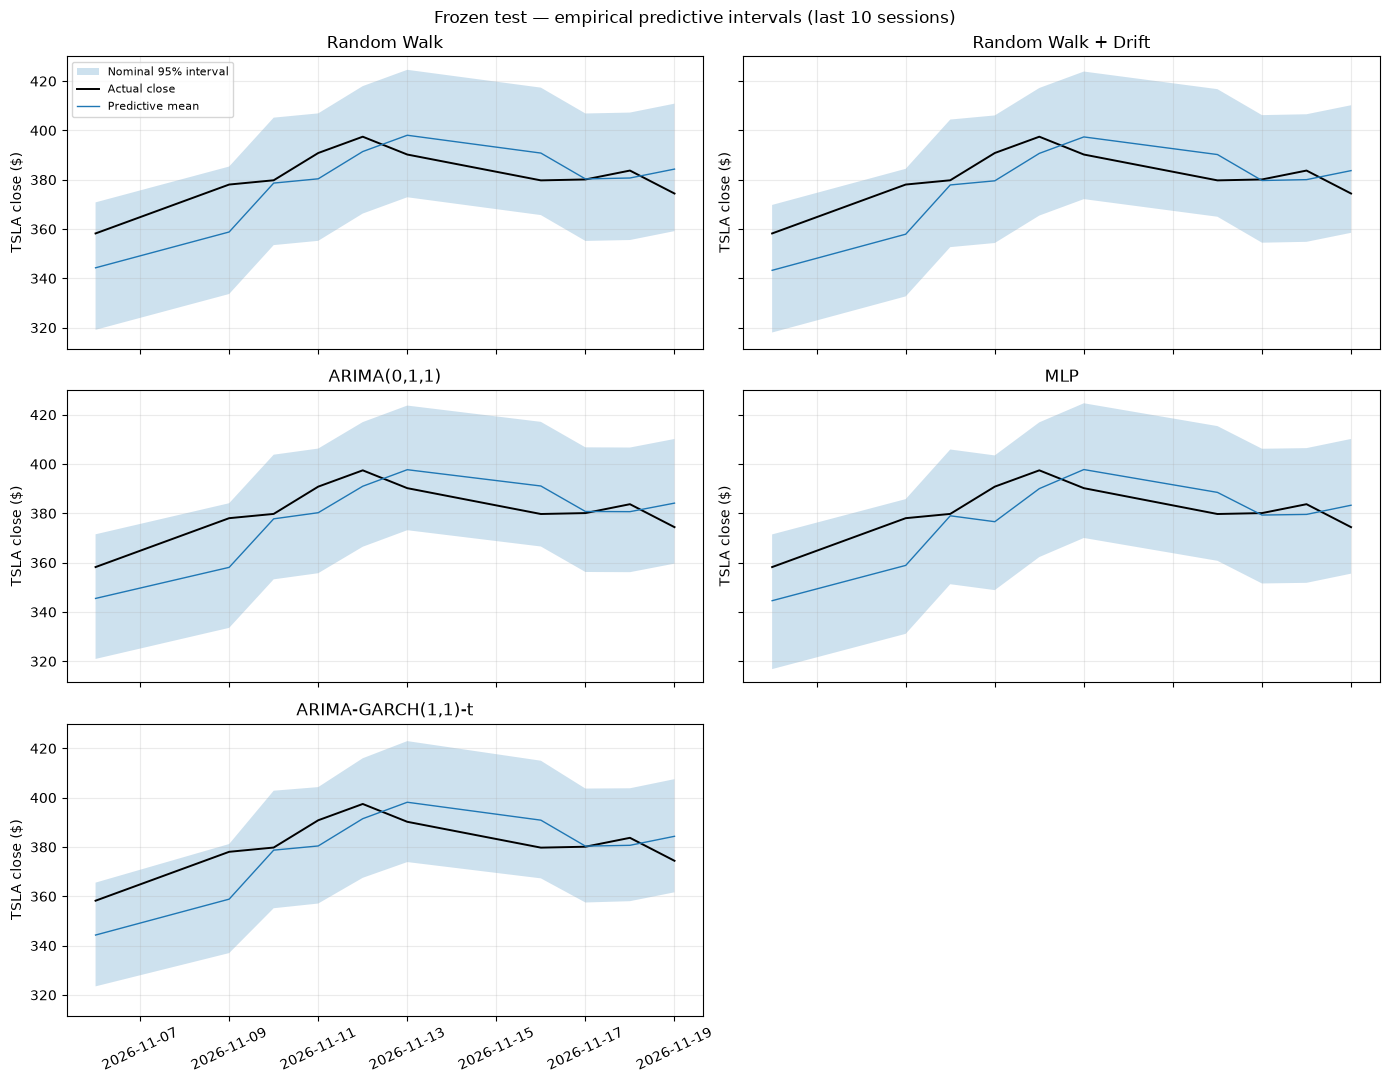

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True, sharey=True)
for ax, (name, df) in zip(axes.flat, tests.items()):
    view = df.tail(10)
    ax.fill_between(view.target_date, view.interval_lower.to_numpy(), view.interval_upper.to_numpy(), alpha=0.22, label="Nominal 95% interval")
    ax.plot(view.target_date, view.y_true, color="black", lw=1.4, label="Actual close")
    ax.plot(view.target_date, view.predictive_mean, lw=1.0, label="Predictive mean")
    ax.set_title(name); ax.set_ylabel("TSLA close ($)"); ax.tick_params(axis="x", rotation=25)
axes.flat[0].legend(loc="best", fontsize=8)
fig.suptitle("Frozen test — empirical predictive intervals (last 10 sessions)")
for ax in axes.flat[len(tests):]:
    ax.set_visible(False)  # hide unused panels
plt.tight_layout(); plt.show()

## 6 · Prospective forecasts (issued before the outcome)
The tables below are read directly from the model-specific append-only histories. **Only realized outcomes may be filled in later; issued predictions must not be retroactively replaced.** If model histories do not yet contain the same latest target, the dashboard shows only their latest *common* target.

In [9]:
# Display all most-recent issued rows first; helps diagnose lagging model notebooks.
latest_issued = pd.concat([df.tail(1).assign(display_model=name) for name, df in live.items() if not df.empty], ignore_index=True)
if latest_issued.empty:
    print("No prospective forecasts have been exported yet.")
else:
    display(latest_issued[["display_model", "origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].round(3))

common_targets = set.intersection(*(set(df.target_date) for df in live.values())) if all(len(df) for df in live.values()) else set()
if not common_targets:
    print("No common prospective target across all models. Run the missing model notebooks first.")
    live_dashboard = pd.DataFrame()
else:
    common_target = max(common_targets)
    live_dashboard = pd.DataFrame([
        {"Model": name, **df.loc[df.target_date.eq(common_target),
         ["origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].iloc[-1].to_dict()}
        for name, df in live.items()
    ]).set_index("Model")
    print("Latest common prospective target:", common_target.date())
    display(live_dashboard.round(3))

/var/folders/rl/m7d_p5px1sd6l0l05dlskw040000gn/T/ipykernel_79589/2482659331.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(latest_issued[["display_model", "origin_date", "target_date", "y_true", "y_pred", "predictive_mean", "interval_lower", "interval_upper"]].round(3))


,display_model,origin_date,target_date,y_true,y_pred,predictive_mean,interval_lower,interval_upper
0,Random Walk,2026-11-27,2026-11-30,NaN,400.000,400.591,375.440,427.130
1,Random Walk + Drift,2026-11-27,2026-11-30,NaN,399.894,399.936,374.715,426.456
2,"ARIMA(0,1,1)",2026-11-27,2026-11-30,NaN,398.538,399.113,374.576,425.127
3,MLP,2026-11-27,2026-11-30,NaN,404.842,404.642,376.894,431.529
4,"ARIMA-GARCH(1,1)-t",2026-11-27,2026-11-30,NaN,400.045,400.769,373.528,428.750


Latest common prospective target: 2026-11-30


/var/folders/rl/m7d_p5px1sd6l0l05dlskw040000gn/T/ipykernel_79589/2482659331.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(live_dashboard.round(3))


,origin_date,target_date,y_true,y_pred,predictive_mean,interval_lower,interval_upper
Model,,,,,,,
Random Walk,2026-11-27,2026-11-30,NaN,400.000,400.591,375.440,427.130
Random Walk + Drift,2026-11-27,2026-11-30,NaN,399.894,399.936,374.715,426.456
"ARIMA(0,1,1)",2026-11-27,2026-11-30,NaN,398.538,399.113,374.576,425.127
MLP,2026-11-27,2026-11-30,NaN,404.842,404.642,376.894,431.529
"ARIMA-GARCH(1,1)-t",2026-11-27,2026-11-30,NaN,400.045,400.769,373.528,428.750


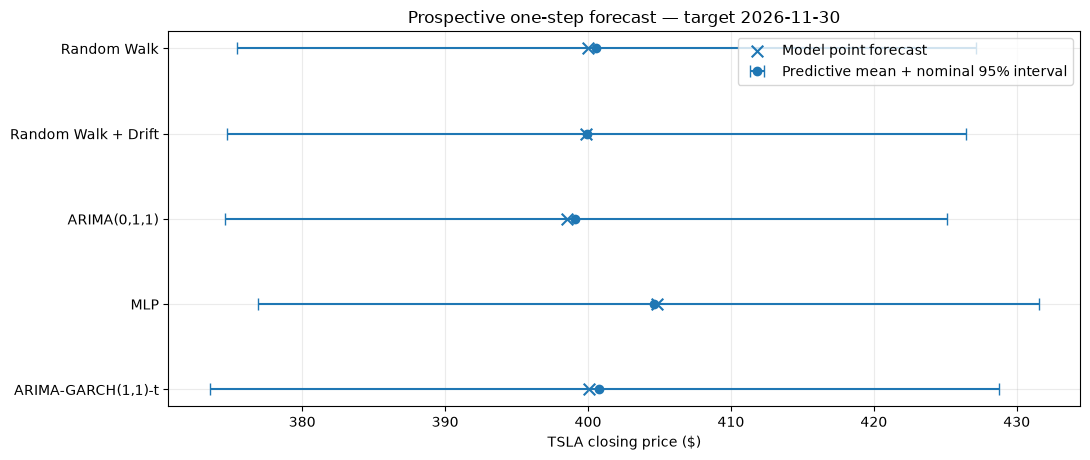

In [10]:
if not live_dashboard.empty:
    fig, ax = plt.subplots(figsize=(11, 4.7))
    order = list(MODEL_FILES)
    display_df = live_dashboard.loc[order]
    y = np.arange(len(order))
    means = display_df["predictive_mean"].to_numpy(float)
    lower = display_df["interval_lower"].to_numpy(float)
    upper = display_df["interval_upper"].to_numpy(float)
    ax.errorbar(means, y, xerr=np.vstack([means-lower, upper-means]),
                fmt="o", capsize=4, label="Predictive mean + nominal 95% interval")
    ax.scatter(display_df["y_pred"], y, marker="x", s=70, label="Model point forecast")
    if display_df["y_true"].notna().all():
        ax.axvline(float(display_df["y_true"].iloc[0]), color="black", ls="--", label="Realized close")
    ax.set_yticks(y, order); ax.invert_yaxis(); ax.set_xlabel("TSLA closing price ($)")
    ax.set_title(f"Prospective one-step forecast — target {common_target.date()}")
    ax.legend(); plt.tight_layout(); plt.show()

## 7 · Interpretation and limitations

- **MMSE principle:** The conditional expectation minimizes expected squared error among forecasts measurable with respect to available information. Here we *approximate* this objective by minimizing validation MSE/RMSE over candidate forecasting procedures.
- **Predictive mean correction:** The empirical predictive mean equals the model point forecast plus the **mean signed validation residual**. A small correction does not imply low volatility or small RMSE.
- **Calibration:** Empirical validation residuals are shifted to obtain prediction intervals. They assume historical residual behavior is informative about future forecast errors; volatility changes can cause miscoverage. Using the same validation period for hyperparameter selection and interval calibration can introduce optimistic bias.
- **ARIMA-GARCH:** Validation log errors are divided by the GARCH volatility forecast, and their empirical quantiles are rescaled by the volatility forecast at each origin, so interval widths follow recent volatility. Point forecasts are essentially a random walk with drift; the comparison of interest is coverage, width, and interval score. It uses a 750-session rolling window (other models: 252) because 252-session GARCH estimates are unstable.
- **Comparability:** All reported test metrics use identical frozen targets. Test data are not used for model selection.
- **Prospective integrity:** Each model's forecast must be issued before its target close; results are not overwritten after observing the outcome.

**Presentation workflow:** run individual model notebooks to refresh and export prospective forecasts; then run this notebook for fast, reproducible comparisons. This notebook performs no model fitting or downloads.

In [11]:
# Combine model predictions into a single DataFrame
predictions = pd.DataFrame({
    name: df.set_index("target_date")["y_pred"]
    for name, df in tests.items()
})

# Compute differences relative to the random walk
deviations = predictions.sub(
    predictions["Random Walk"], axis=0
)

display(deviations.describe().round(4))

,Random Walk,Random Walk + Drift,"ARIMA(0,1,1)",MLP,"ARIMA-GARCH(1,1)-t"
count,258.0,258.0000,258.0000,258.0000,258.0000
mean,0.0,0.1806,0.0275,0.2986,0.1381
std,0.0,0.2609,1.0190,1.8025,0.1921
min,0.0,-0.4716,-3.2748,-5.0656,-0.1992
25%,0.0,0.0132,-0.6257,-0.8670,-0.0166
50%,0.0,0.2172,-0.0018,0.2277,0.1209
75%,0.0,0.3750,0.5672,1.3603,0.2422
max,0.0,0.7061,6.1377,5.0052,0.6816


In [12]:
for name in predictions.columns:
    difference = deviations[name]

    print(
        f"{name}: "
        f"Identical to RW = "
        f"{np.allclose(difference, 0)}, "
        f"Mean absolute difference = "
        f"{difference.abs().mean():.4f}, "
        f"Max absolute difference = "
        f"{difference.abs().max():.4f}"
    )

Random Walk: Identical to RW = True, Mean absolute difference = 0.0000, Max absolute difference = 0.0000
Random Walk + Drift: Identical to RW = False, Mean absolute difference = 0.2711, Max absolute difference = 0.7061
ARIMA(0,1,1): Identical to RW = False, Mean absolute difference = 0.7520, Max absolute difference = 6.1377
MLP: Identical to RW = False, Mean absolute difference = 1.4296, Max absolute difference = 5.0656
ARIMA-GARCH(1,1)-t: Identical to RW = False, Mean absolute difference = 0.1811, Max absolute difference = 0.6816


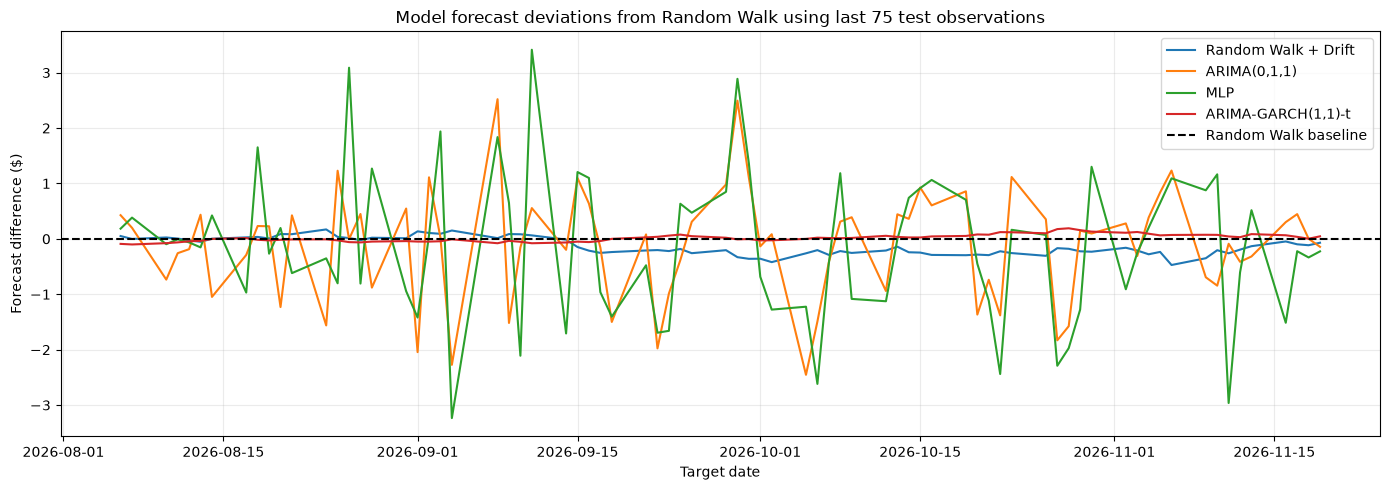

In [13]:
last_n = 75

fig, ax = plt.subplots(figsize=(14, 5))

for name in deviations.columns:
    if name != "Random Walk":
        view = deviations[name].tail(last_n)
        ax.plot(view.index, view, label=name)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    label="Random Walk baseline"
)

ax.set_title("Model forecast deviations from Random Walk using last 75 test observations")
ax.set_ylabel("Forecast difference ($)")
ax.set_xlabel("Target date")
ax.legend()

plt.tight_layout()
plt.show()

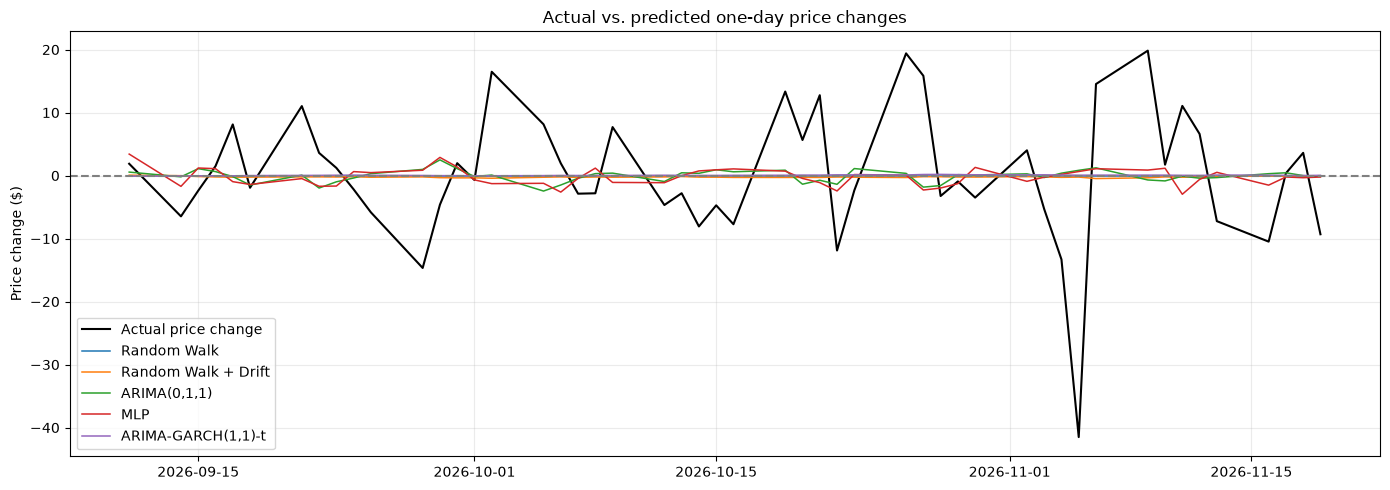

In [14]:
actual = tests["Random Walk"].set_index(
    "target_date"
)["y_true"]

actual_change = actual - predictions["Random Walk"]

predicted_changes = predictions.sub(
    predictions["Random Walk"], axis=0
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    actual_change.tail(50),
    color="black",
    label="Actual price change",
    lw=1.5
)

for name in predicted_changes.columns:
    ax.plot(
        predicted_changes[name].tail(50),
        label=name,
        lw=1.1
    )

ax.axhline(0, color="gray", linestyle="--")
ax.set_ylabel("Price change ($)")
ax.set_title("Actual vs. predicted one-day price changes")
ax.legend()
#ax.set_ylim(-4, 4)

plt.tight_layout()
plt.show()

In [15]:
coverage_by_model = pd.DataFrame({
    name: (
        df.set_index("target_date")["y_true"].between(
            df.set_index("target_date")["interval_lower"],
            df.set_index("target_date")["interval_upper"]
        )
    )
    for name, df in tests.items()
})

# Display every date where at least one model failed
missed_dates = coverage_by_model.loc[
    ~coverage_by_model.all(axis=1)
]

display(missed_dates)

,Random Walk,Random Walk + Drift,"ARIMA(0,1,1)",MLP,"ARIMA-GARCH(1,1)-t"
target_date,,,,,
2025-11-13,False,False,False,False,False
2025-11-24,True,True,True,True,False
2026-04-02,True,True,True,True,False
2026-04-15,False,False,False,False,False
2026-06-05,False,False,False,True,False
2026-06-23,True,True,True,True,False
2026-06-29,False,False,False,False,False
2026-07-02,False,False,False,False,False
2026-07-06,True,True,True,False,False


In [16]:
disagreement = coverage_by_model.nunique(axis=1) > 1

print("Dates with coverage disagreement:", disagreement.sum())

display(coverage_by_model.loc[disagreement])

Dates with coverage disagreement: 5


,Random Walk,Random Walk + Drift,"ARIMA(0,1,1)",MLP,"ARIMA-GARCH(1,1)-t"
target_date,,,,,
2025-11-24,True,True,True,True,False
2026-04-02,True,True,True,True,False
2026-06-05,False,False,False,True,False
2026-06-23,True,True,True,True,False
2026-07-06,True,True,True,False,False
